# Machine Learning - Assignment 2
## Comparing Classification Models on the UCI Adult (Census Income) Dataset

**Student Name:** Rakshantha M
**Student ID:** __2026AK05368_____________
**Date:** 26-Oct-2026

---
Five classifiers (Logistic Regression, Decision Tree, KNN, Naive Bayes, SVM) are trained
on the same dataset and compared on six evaluation metrics: Accuracy, AUC, Precision,
Recall, F1, and MCC. The best models and preprocessing pipeline are saved for the
companion Streamlit app.


In [ ]:
%pip install numpy pandas joblib matplotlib seaborn
%pip install scikit-learn
import time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, roc_curve
)

np.random.seed(42)
sns.set_style('whitegrid')
print("Libraries imported")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Libraries imported


## Section 1: Dataset

**UCI Adult / Census Income dataset** — predicts whether a person's annual income
exceeds $50K based on census attributes (age, education, occupation, hours worked,
etc.). Source: [UCI ML Repository](https://archive.ics.uci.edu/dataset/2/adult).

- 48,842 instances, 14 features, binary target
- Mix of numeric and categorical features, with some missing values (marked `?`)

In [ ]:
cols = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status',
        'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss',
        'hours_per_week', 'native_country', 'income']

df = pd.read_csv('data/adult_raw.csv', header=None, names=cols, na_values='?', skipinitialspace=True)

dataset_name = "UCI Adult (Census Income)"
dataset_source = "https://archive.ics.uci.edu/dataset/2/adult"
n_samples_raw, n_features_raw = df.shape[0], df.shape[1] - 1

print(f"Shape: {df.shape}")
display(df.head())

Shape: (48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
display(df.info())
print()
print("Missing values per column:")
display(df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education_num   48842 non-null  int64
 5   marital_status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital_gain    48842 non-null  int64
 11  capital_loss    48842 non-null  int64
 12  hours_per_week  48842 non-null  int64
 13  native_country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


None


Missing values per column:


workclass         2799
occupation        2809
native_country     857
dtype: int64

## Section 2: Exploratory Data Analysis

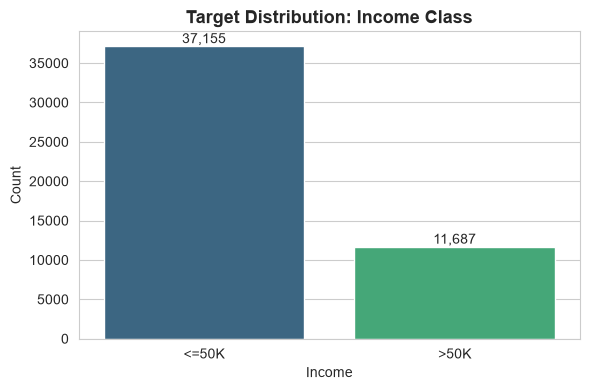

income
<=50K    0.761
>50K     0.239
Name: proportion, dtype: float64


In [ ]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='income', hue='income', palette='viridis', legend=False)
ax.set_title('Target Distribution: Income Class', fontsize=13, fontweight='bold')
ax.set_xlabel('Income')
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

print(df['income'].value_counts(normalize=True).round(3))

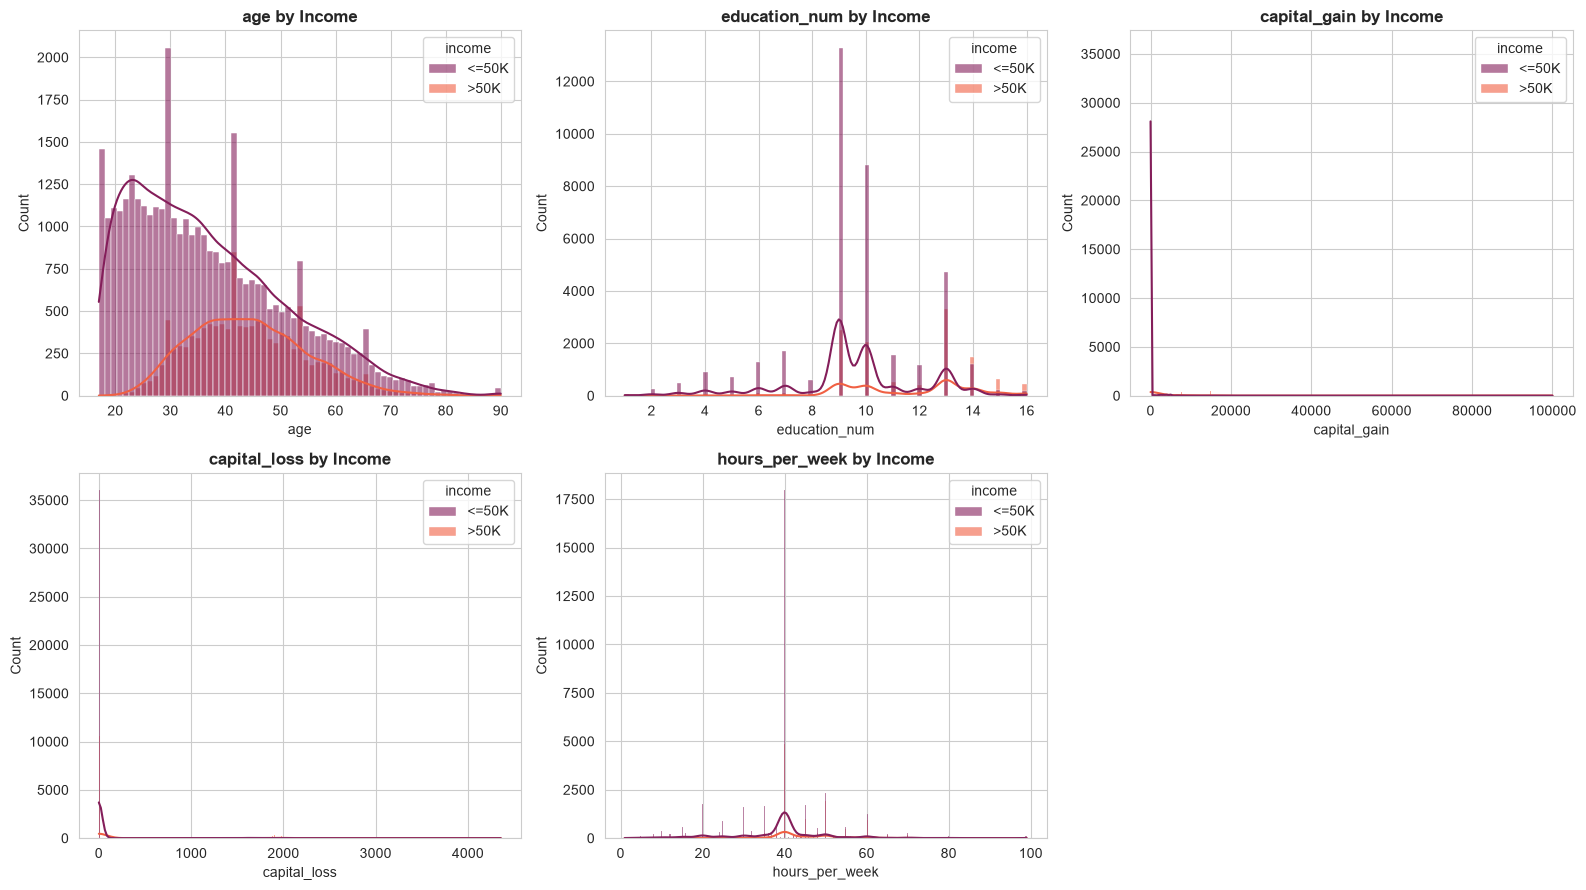

In [ ]:
numeric_cols_raw = ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
palette = sns.color_palette('rocket', 2)

for i, col in enumerate(numeric_cols_raw):
    sns.histplot(data=df, x=col, hue='income', palette=palette, kde=True, ax=axes[i], alpha=0.6)
    axes[i].set_title(f'{col} by Income', fontweight='bold')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

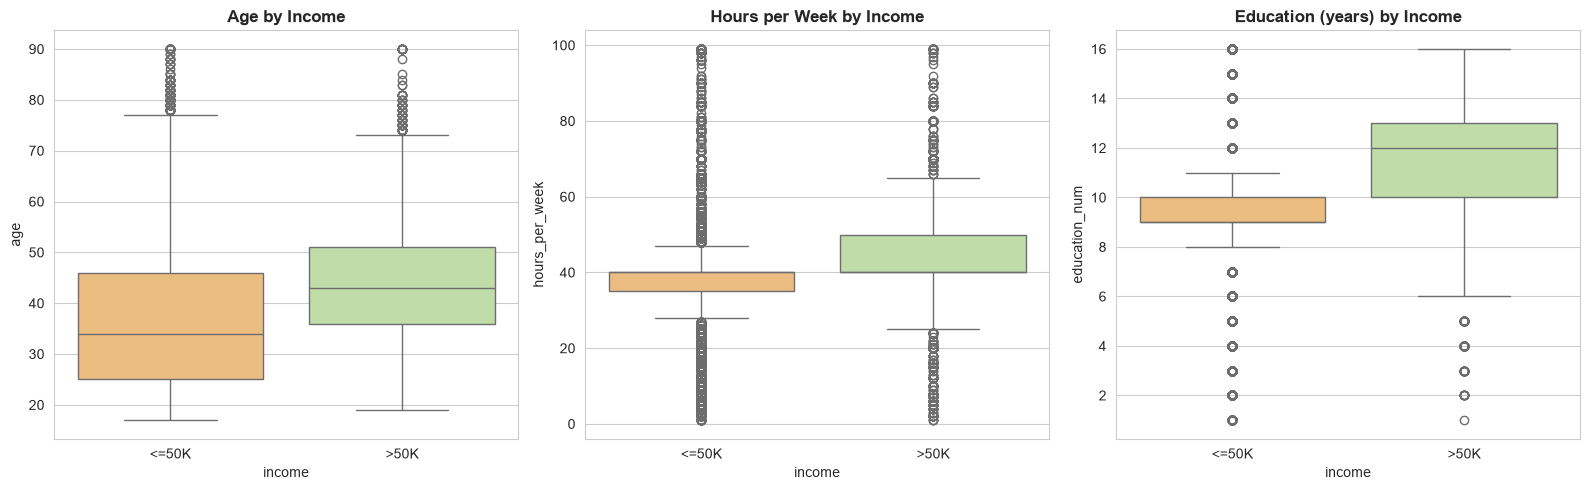

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df, x='income', y='age', hue='income', palette='Spectral', ax=axes[0], legend=False)
axes[0].set_title('Age by Income', fontweight='bold')

sns.boxplot(data=df, x='income', y='hours_per_week', hue='income', palette='Spectral', ax=axes[1], legend=False)
axes[1].set_title('Hours per Week by Income', fontweight='bold')

sns.boxplot(data=df, x='income', y='education_num', hue='income', palette='Spectral', ax=axes[2], legend=False)
axes[2].set_title('Education (years) by Income', fontweight='bold')

plt.tight_layout()
plt.show()

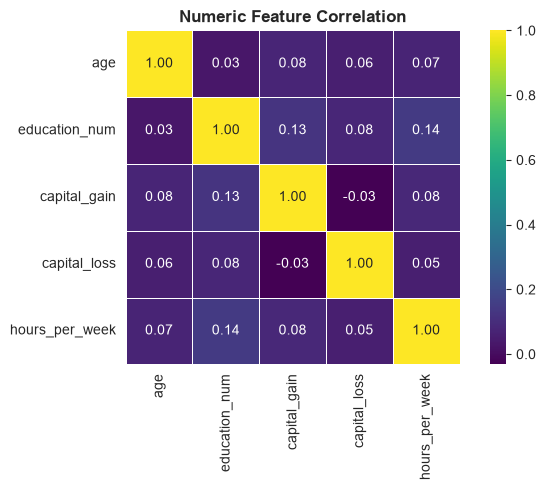

In [ ]:
plt.figure(figsize=(7, 5))
corr = df[numeric_cols_raw].corr()
sns.heatmap(corr, annot=True, cmap='viridis', fmt='.2f', square=True, linewidths=0.5)
plt.title('Numeric Feature Correlation', fontweight='bold')
plt.tight_layout()
plt.show()

**EDA takeaways:**
- Classes are imbalanced (~76% ≤50K, ~24% >50K) — motivates using AUC/F1/MCC alongside accuracy.
- Higher earners skew toward more education years, more hours worked, and (unsurprisingly) higher age — all three show clear separation by income class.
- Numeric features aren't strongly correlated with each other, so no redundancy to prune there.
- `native_country` is dominated by United-States (~90%); the long tail of ~40 other countries has very few rows each.

## Section 3: Data Cleaning and Preprocessing

In [ ]:
# fnlwgt is a census sampling weight, not predictive of income -> drop
# education is a redundant string version of education_num -> drop
df = df.drop(columns=['fnlwgt', 'education'])

# Collapse native_country: dominant US + long noisy tail of ~40 countries with
# very few rows each -> one-hotting all of them adds mostly noise columns.
df['native_country'] = np.where(df['native_country'] == 'United-States', 'United-States', 'Other')

# Drop rows with missing workclass/occupation (small %, no natural "unknown" category)
df = df.dropna(subset=['workclass', 'occupation'])

# Binary target
df['income'] = (df['income'] == '>50K').astype(int)

print(f"Shape after cleaning: {df.shape}")

Shape after cleaning: (46033, 13)


In [ ]:
# Stratified subsample: keeps SVM training and Streamlit Cloud deployment fast,
# while staying ~12x over the assignment's 500-instance minimum.
SAMPLE_SIZE = 6000
df_sample, _ = train_test_split(df, train_size=SAMPLE_SIZE, stratify=df['income'], random_state=42)

numeric_cols = ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
categorical_cols = ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

X = df_sample[numeric_cols + categorical_cols]
y = df_sample['income']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

n_samples = df_sample.shape[0]
n_features = len(numeric_cols) + len(categorical_cols)
train_samples, test_samples = X_train.shape[0], X_test.shape[0]
train_test_ratio = round(train_samples / n_samples, 2)

print(f"Sampled: {n_samples} rows, {n_features} raw features")
print(f"Train: {train_samples}, Test: {test_samples}, split ratio: {train_test_ratio:.1%}")

Sampled: 6000 rows, 12 raw features
Train: 4800, Test: 1200, split ratio: 80.0%


In [ ]:
# Held-out test split, in original (pre-encoding) feature form, for the Streamlit app.
# The app loads a saved pipeline (preprocessing + model bundled together) and scores
# this CSV directly -- no retraining happens in the app.
test_data = X_test.copy()
test_data['income'] = y_test.values
test_data.to_csv('test_data.csv', index=False)
print(f"test_data.csv written: {test_data.shape}")
display(test_data.head())

test_data.csv written: (1200, 13)


,age,education_num,capital_gain,capital_loss,hours_per_week,workclass,marital_status,occupation,relationship,race,sex,native_country,income
21518,61,10,0,0,25,Private,Divorced,Other-service,Not-in-family,White,Male,United-States,0
16297,46,9,0,0,40,Private,Married-civ-spouse,Craft-repair,Husband,White,Male,United-States,0
8028,47,9,0,0,32,Private,Divorced,Other-service,Own-child,White,Female,United-States,0
31004,28,9,0,0,40,Private,Married-civ-spouse,Transport-moving,Husband,White,Male,United-States,0
20584,67,13,0,0,30,Self-emp-not-inc,Married-civ-spouse,Sales,Husband,White,Male,United-States,0


## Section 4: Model Training

Each model is wrapped in the same `preprocessor + classifier` pipeline, so every
saved `.joblib` file is self-contained: it accepts the raw feature columns directly
(no separate scaler/encoder step needed downstream).

In [ ]:
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), categorical_cols),
])

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=42),
}
print(f"{len(models)} models configured")

5 models configured


In [ ]:
results = {}
fitted_pipelines = {}
roc_data = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', clf)])

    t0 = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - t0

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_proba),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'MCC': matthews_corrcoef(y_test, y_pred),
    }
    metrics['Training Time (s)'] = round(train_time, 3)

    results[name] = metrics
    fitted_pipelines[name] = pipe
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_data[name] = (fpr, tpr, metrics['AUC'])

    print(f"✓ {name} trained in {train_time:.2f}s — Accuracy: {metrics['Accuracy']:.4f}, F1: {metrics['F1']:.4f}")

✓ Logistic Regression trained in 0.05s — Accuracy: 0.8492, F1: 0.6617
✓ Decision Tree trained in 0.02s — Accuracy: 0.8442, F1: 0.6492
✓ KNN trained in 0.01s — Accuracy: 0.8275, F1: 0.6202
✓ Naive Bayes trained in 0.02s — Accuracy: 0.6775, F1: 0.5843
✓ Support Vector Machine trained in 1.43s — Accuracy: 0.8475, F1: 0.6433


## Section 5: Evaluation and Comparison

In [ ]:
results_df = pd.DataFrame(results).T.round(4)
display(results_df)

,Accuracy,AUC,Precision,Recall,F1,MCC,Training Time (s)
Logistic Regression,0.8492,0.8995,0.7468,0.5940,0.6617,0.5724,0.054
Decision Tree,0.8442,0.8697,0.7362,0.5805,0.6492,0.5572,0.018
KNN,0.8275,0.8825,0.6842,0.5671,0.6202,0.5136,0.011
Naive Bayes,0.6775,0.8676,0.4297,0.9128,0.5843,0.4435,0.023
Support Vector Machine,0.8475,0.8948,0.7674,0.5537,0.6433,0.5613,1.432


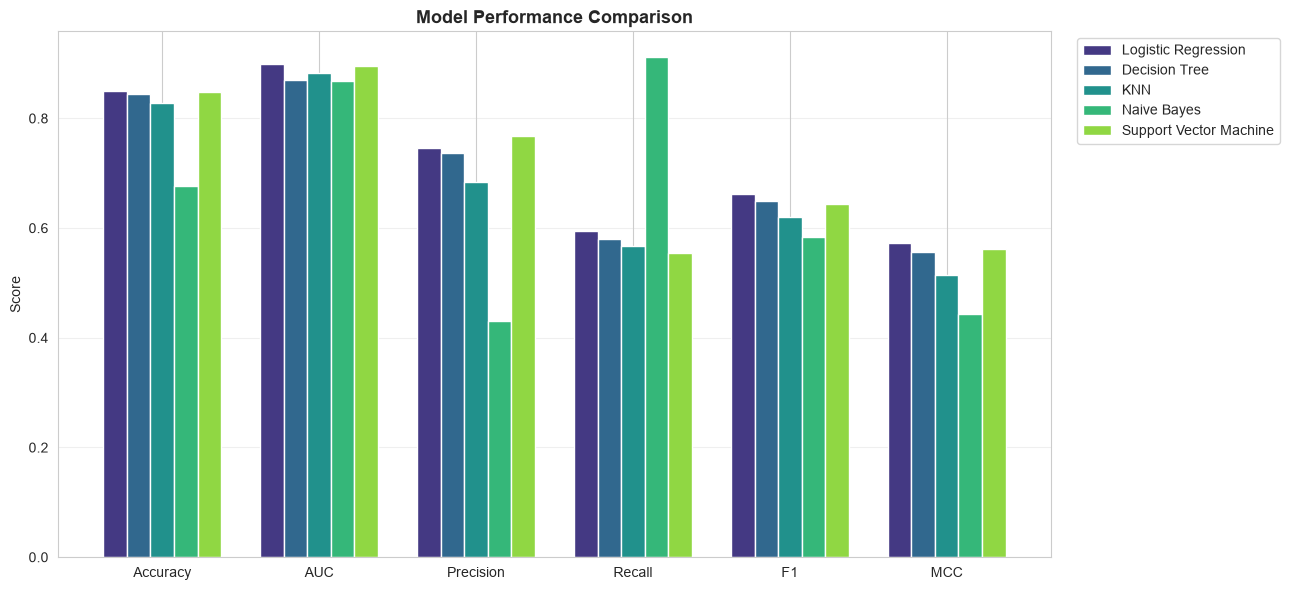

In [ ]:
metric_cols = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']
plot_df = results_df[metric_cols]

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(metric_cols))
width = 0.15
palette = sns.color_palette('viridis', len(plot_df))

for i, (name, row) in enumerate(plot_df.iterrows()):
    ax.bar(x + i * width, row.values, width, label=name, color=palette[i])

ax.set_xticks(x + width * (len(plot_df) - 1) / 2)
ax.set_xticklabels(metric_cols)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison', fontsize=13, fontweight='bold')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

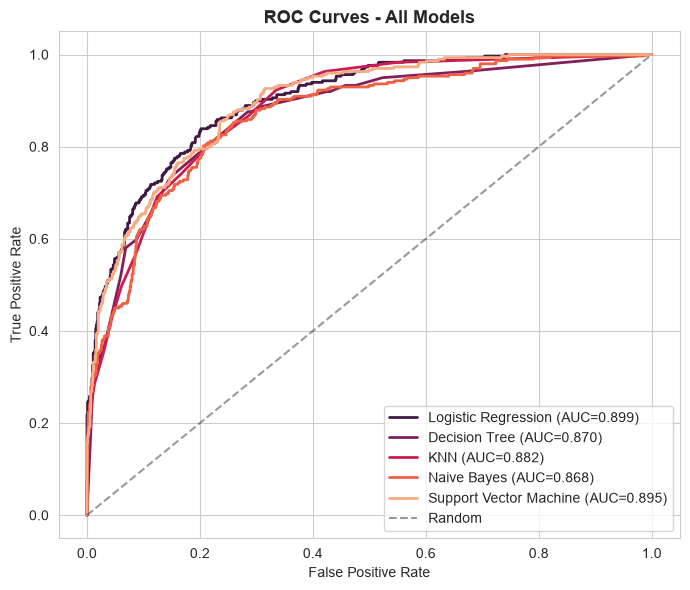

In [ ]:
plt.figure(figsize=(7, 6))
palette = sns.color_palette('rocket', len(roc_data))
for i, (name, (fpr, tpr, auc)) in enumerate(roc_data.items()):
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=palette[i], linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Models', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

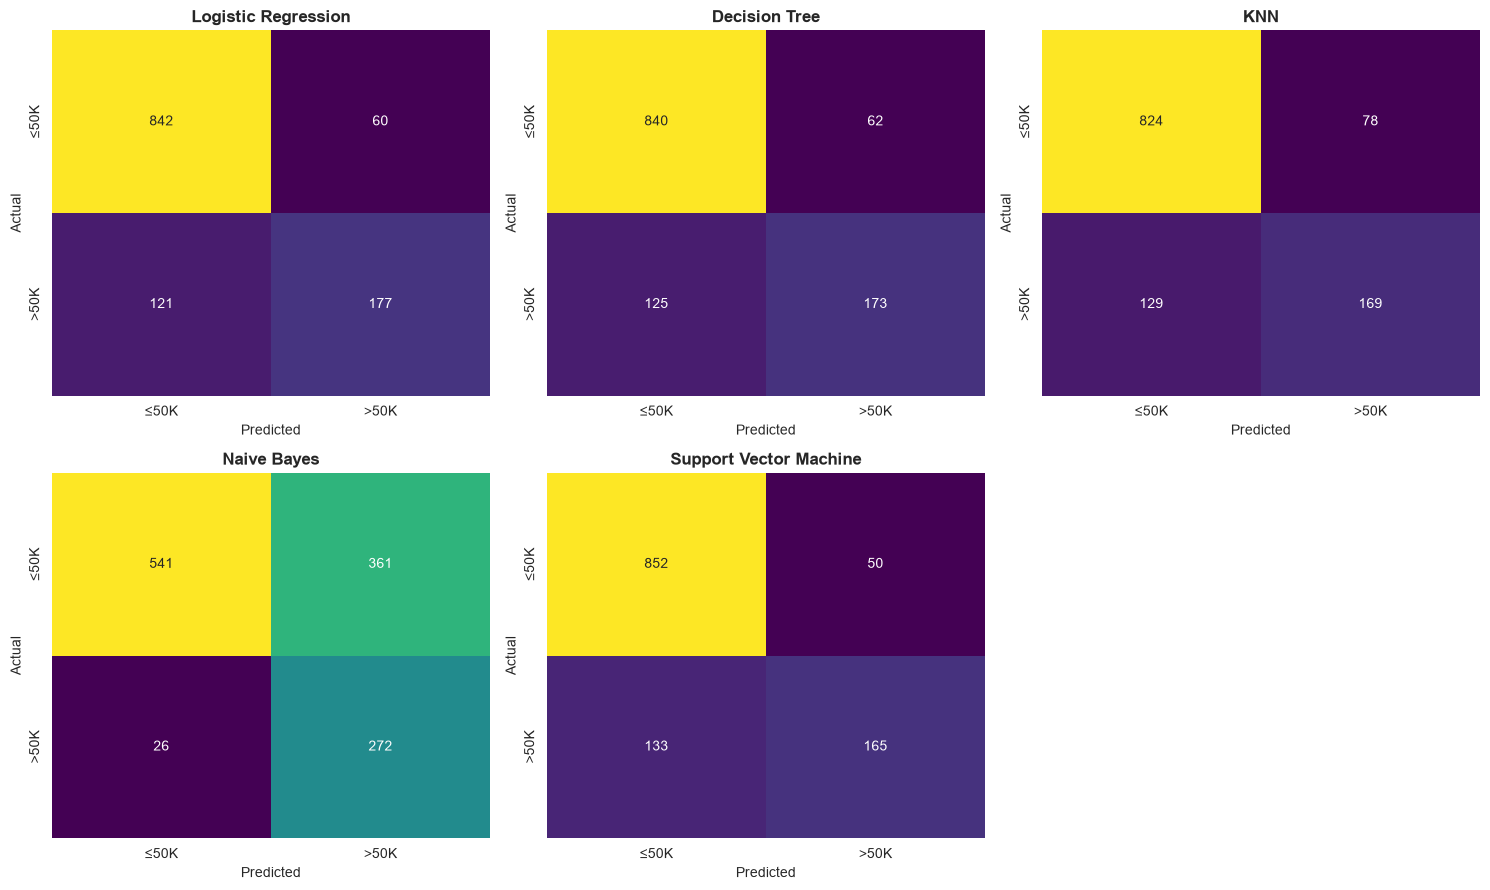

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, pipe) in enumerate(fitted_pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis', ax=axes[i], cbar=False,
                xticklabels=['≤50K', '>50K'], yticklabels=['≤50K', '>50K'])
    axes[i].set_title(name, fontweight='bold')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

## Section 6: Save Models and Artifacts

In [ ]:
name_to_file = {
    'Logistic Regression': 'logistic_regression',
    'Decision Tree': 'decision_tree',
    'KNN': 'knn',
    'Naive Bayes': 'naive_bayes',
    'Support Vector Machine': 'svm',
}

for name, pipe in fitted_pipelines.items():
    fname = f"model/{name_to_file[name]}.joblib"
    joblib.dump(pipe, fname)
    print(f"Saved {fname}")

results_df.to_csv('model/comparison_table.csv')
print("\nSaved model/comparison_table.csv")

Saved model/logistic_regression.joblib
Saved model/decision_tree.joblib
Saved model/knn.joblib
Saved model/naive_bayes.joblib
Saved model/svm.joblib

Saved model/comparison_table.csv


## Section 7: Observations

**Logistic Regression** comes out on top overall — best AUC (0.900) and F1 (0.662),
second-best accuracy, and it trains almost instantly. A linear decision boundary is
evidently enough to separate income classes on these features; the dataset doesn't
reward extra model complexity.

**Decision Tree** (depth-capped at 8 to control overfitting) lands just behind
Logistic Regression across the board — a reasonable, interpretable second choice,
and the fastest to train.

**KNN** (k=15) is the weakest performer on accuracy and F1. Distance-based methods
are sensitive to the mixed numeric/one-hot-encoded feature space here — the
one-hot dimensions dilute the numeric features' contribution to distance.

**Naive Bayes** is the standout outlier: by far the lowest accuracy (0.68) and
precision (0.43), but the highest recall (0.91) of any model. Its independence
assumption is clearly violated here (age, education, and hours-worked are
correlated with each other), which hurts calibration — but the model compensates
by flagging almost every true high-earner, at the cost of many false positives.
If the goal were "never miss a high earner" (e.g. a lead-scoring use case willing
to over-flag), Naive Bayes would be the pick.

**SVM (RBF kernel)** achieves the best precision (0.77) and a strong AUC (0.895),
but trades off recall — it's the most conservative model about predicting the
positive class.

**Overall winner: Logistic Regression.** It leads on AUC, F1, and MCC — the three
metrics that matter most on an imbalanced binary target — while also being the
cheapest model to train and the easiest to explain to a non-technical
stakeholder.